# 07 · Explainability: what the model learned, and how far to trust it

A single SHAP chart answers one question: which features moved this model's scores.
This notebook asks the harder questions behind it:

1. **Do different methods and different good models agree** on what matters? (Rashomon)
2. **What shape does each effect have**, and is a global curve hiding opposite effects in
   sub-populations? (ALE vs PDP+ICE, regional effects)
3. **Which features act together?** (Friedman's H statistic, the EBM's learned pairs)
4. **Where and when does the model see risk?** (spatial and temporal attributions)
5. **Why did it score a particular accident as it did, and what would change it?**
   (local attributions, counterfactuals)
6. **Are the explanations reliable?** (stability across refits, faithfulness tests,
   agreement with a glass-box model)
7. **Where does it fail?** (error analysis)

Attributions explain the *model*, not the world: they are associations learned from
traffic-feed data, not causes of major traffic impact. Section 9 lists the limits.

In [1]:
import json

import dice_ml
import effector
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from raiutils.exceptions import UserConfigValidationException

from accidents import benchmark, calibrate, config, explain, features, models, plots

plots.use_style()
pd.set_option("display.width", 160)
FINAL = config.ROOT / "data" / "processed" / "final"
rng = np.random.default_rng(config.SEED)

frozen = json.loads((FINAL / "frozen.json").read_text())
calibrator = json.loads((FINAL / "calibrator.json").read_text())
chosen = frozen["model"]
spec = models.MODELS[chosen]
bundle = joblib.load(FINAL / "model.joblib")  # the final fit chosen in notebook 06
model, medians = bundle["model"], bundle["medians"]

table = pd.read_parquet(config.MODEL_TABLE)
test = table[table["split"] == "test"].reset_index(drop=True)
train = table[table["split"] == "train"].reset_index(drop=True)


def predict(frame: pd.DataFrame) -> np.ndarray:
    """Calibrated probability of Severity 4, exactly as the dashboard will compute it."""
    x, _ = benchmark.prepare(spec, frame.assign(y=0), medians)
    return calibrate.apply(calibrator, model.predict_proba(x)[:, 1])


sample = test.sample(30_000, random_state=config.SEED).reset_index(drop=True)
x_sample = sample[features.FEATURES]
contributions, base_value = explain.tree_contributions(model, x_sample)
print(f"explaining {chosen}; base value {base_value:.3f} log-odds; {len(sample):,} test rows")

FAMILY_COLOR = {family: plots.SERIES[i] for i, family in enumerate(explain.FAMILIES)}

explaining lightgbm; base value -4.832 log-odds; 30,000 test rows


## 1 · Global importance from three directions

- **Mean |SHAP|:** the average size of each feature's push on the model's log-odds.
- **Permutation importance:** how much average precision on test months drops when a
  feature's values are shuffled. Model-agnostic, and measured on outcomes, not scores.
- **Families:** SHAP values add up, so place, time, weather and road can be compared as
  wholes.

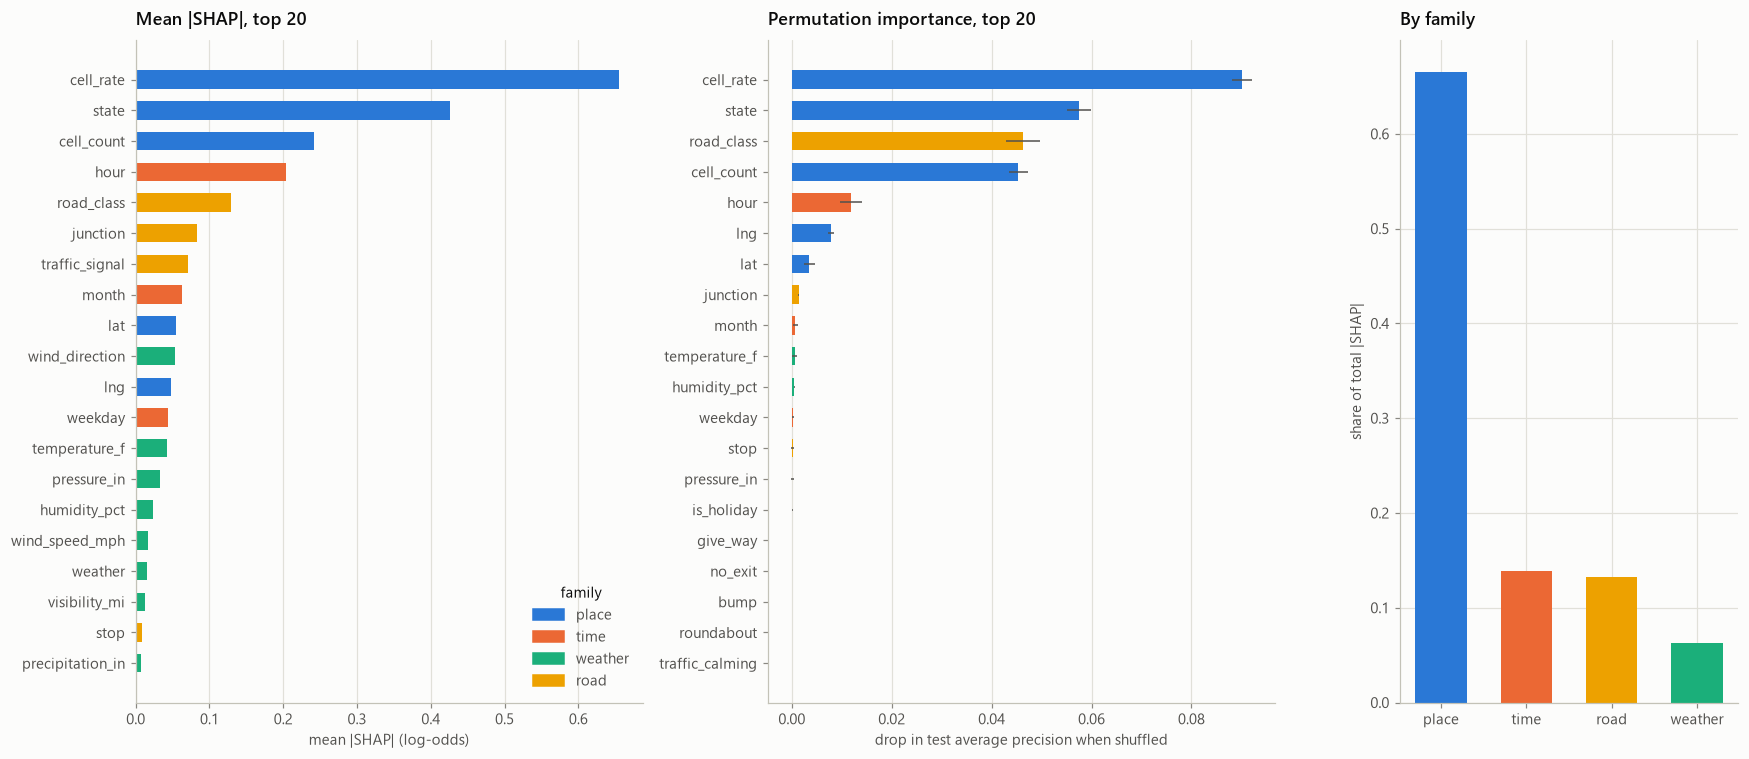

,mean_abs_shap,permutation_ap_drop
cell_rate,0.6545,0.0901
state,0.4266,0.0574
cell_count,0.2416,0.0454
hour,0.2031,0.0119
road_class,0.1290,0.0463
junction,0.0837,0.0014
traffic_signal,0.0712,-0.0006
month,0.0632,0.0007
lat,0.0541,0.0035
wind_direction,0.0528,-0.0007


In [2]:
shap_importance = explain.mean_absolute(contributions)
perm_rows = test.sample(100_000, random_state=config.SEED + 1).reset_index(drop=True)
permutation = explain.permutation_importance(
    lambda frame: predict(frame), perm_rows[features.FEATURES], perm_rows["y"].to_numpy(), repeats=3
)
family_share = explain.mean_absolute(explain.family_contributions(contributions))
family_share = family_share / family_share.sum()

fig, axes = plt.subplots(1, 3, figsize=(16, 7), gridspec_kw={"width_ratios": [1.2, 1.2, 0.8]})
top = shap_importance.head(20)[::-1]
axes[0].barh(
    top.index, top.values, height=0.6, color=[FAMILY_COLOR[explain.FAMILY_OF[f]] for f in top.index]
)
axes[0].set_xlabel("mean |SHAP| (log-odds)")
axes[0].set_title("Mean |SHAP|, top 20")
perm = permutation.head(20)[::-1]
axes[1].barh(
    perm.index,
    perm["ap_drop"],
    xerr=perm["sd"],
    height=0.6,
    color=[FAMILY_COLOR[explain.FAMILY_OF[f]] for f in perm.index],
    error_kw={"ecolor": plots.INK_SECONDARY, "elinewidth": 1},
)
axes[1].set_xlabel("drop in test average precision when shuffled")
axes[1].set_title("Permutation importance, top 20")
axes[2].bar(
    family_share.index,
    family_share.values,
    width=0.6,
    color=[FAMILY_COLOR[f] for f in family_share.index],
)
axes[2].set_ylabel("share of total |SHAP|")
axes[2].set_title("By family")
for ax in axes[:2]:
    ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOR.values()]
axes[0].legend(handles, FAMILY_COLOR.keys(), loc="lower right", title="family")
plt.tight_layout()
plt.show()
display(
    pd.DataFrame({"mean_abs_shap": shap_importance, "permutation_ap_drop": permutation["ap_drop"]})
    .sort_values("mean_abs_shap", ascending=False)
    .head(15)
    .round(4)
)

### Do other good models, and a glass-box model, agree? (the Rashomon view)

Several models reach similar accuracy (notebook 05). If they rely on the same features,
the explanation is a property of the data, not of one model's quirks. Rankings are
compared with Kendall's τ (1 = identical order, 0 = unrelated).

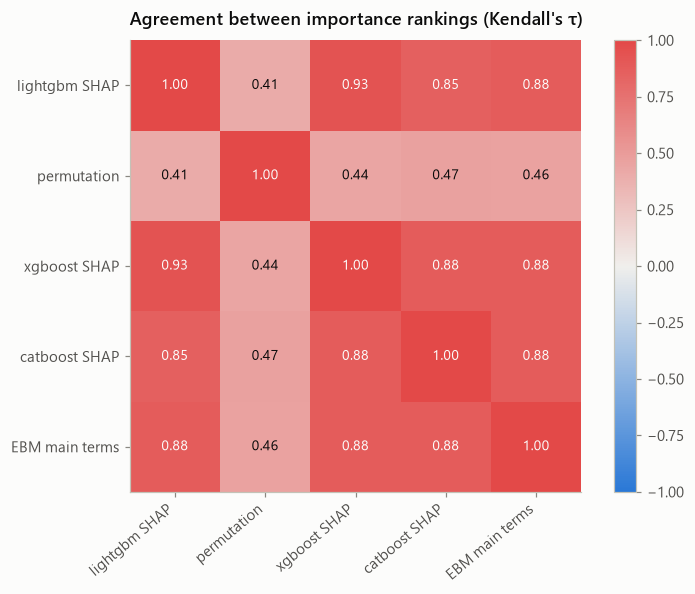

In [3]:
rankings = {f"{chosen} SHAP": shap_importance, "permutation": permutation["ap_drop"]}
for other in ("lightgbm", "xgboost", "catboost"):
    file = benchmark.OUT / f"{other}.joblib"
    if other == chosen or not file.exists():
        continue
    other_model = joblib.load(file)["model"]
    other_contrib, _ = explain.tree_contributions(other_model, x_sample)
    rankings[f"{other} SHAP"] = explain.mean_absolute(other_contrib)
ebm_file = benchmark.OUT / "ebm.joblib"
if ebm_file.exists():
    ebm = joblib.load(ebm_file)["model"]
    terms = pd.Series(ebm.term_importances(), index=ebm.term_names_)
    rankings["EBM main terms"] = terms[[t for t in terms.index if " & " not in t]]
agreement = explain.rank_agreement(rankings)

fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(agreement.astype(float), vmin=-1, vmax=1, cmap=plots.DIVERGING)
ax.set_xticks(range(len(agreement)), agreement.columns, rotation=40, ha="right")
ax.set_yticks(range(len(agreement)), agreement.index)
for i in range(len(agreement)):
    for j in range(len(agreement)):
        value = float(agreement.iloc[i, j])
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color=plots.SURFACE if abs(value) > 0.6 else plots.INK,
        )
ax.set_title("Agreement between importance rankings (Kendall's τ)")
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 2 · Effect shapes: ALE against PDP and ICE

A partial-dependence plot (PDP) averages predictions after forcing a feature to each
value for *every* row, including impossible combinations such as 95 °F with snow. When
features are correlated that extrapolation can mislead. Accumulated local effects (ALE)
only compare nearby values within real rows, so they stay inside the data. Thin lines are
individual conditional expectations (ICE) for 100 random accidents; when they fan out,
the feature's effect depends on other features.

effector needs complete rows, so the curves below use the 94% of sampled accidents with
every weather reading present. A missing reading carries its own signal (notebook 02);
its contribution appears in the SHAP values of section 1, not in these curves.

28,179 of 30,000 sampled rows have every reading


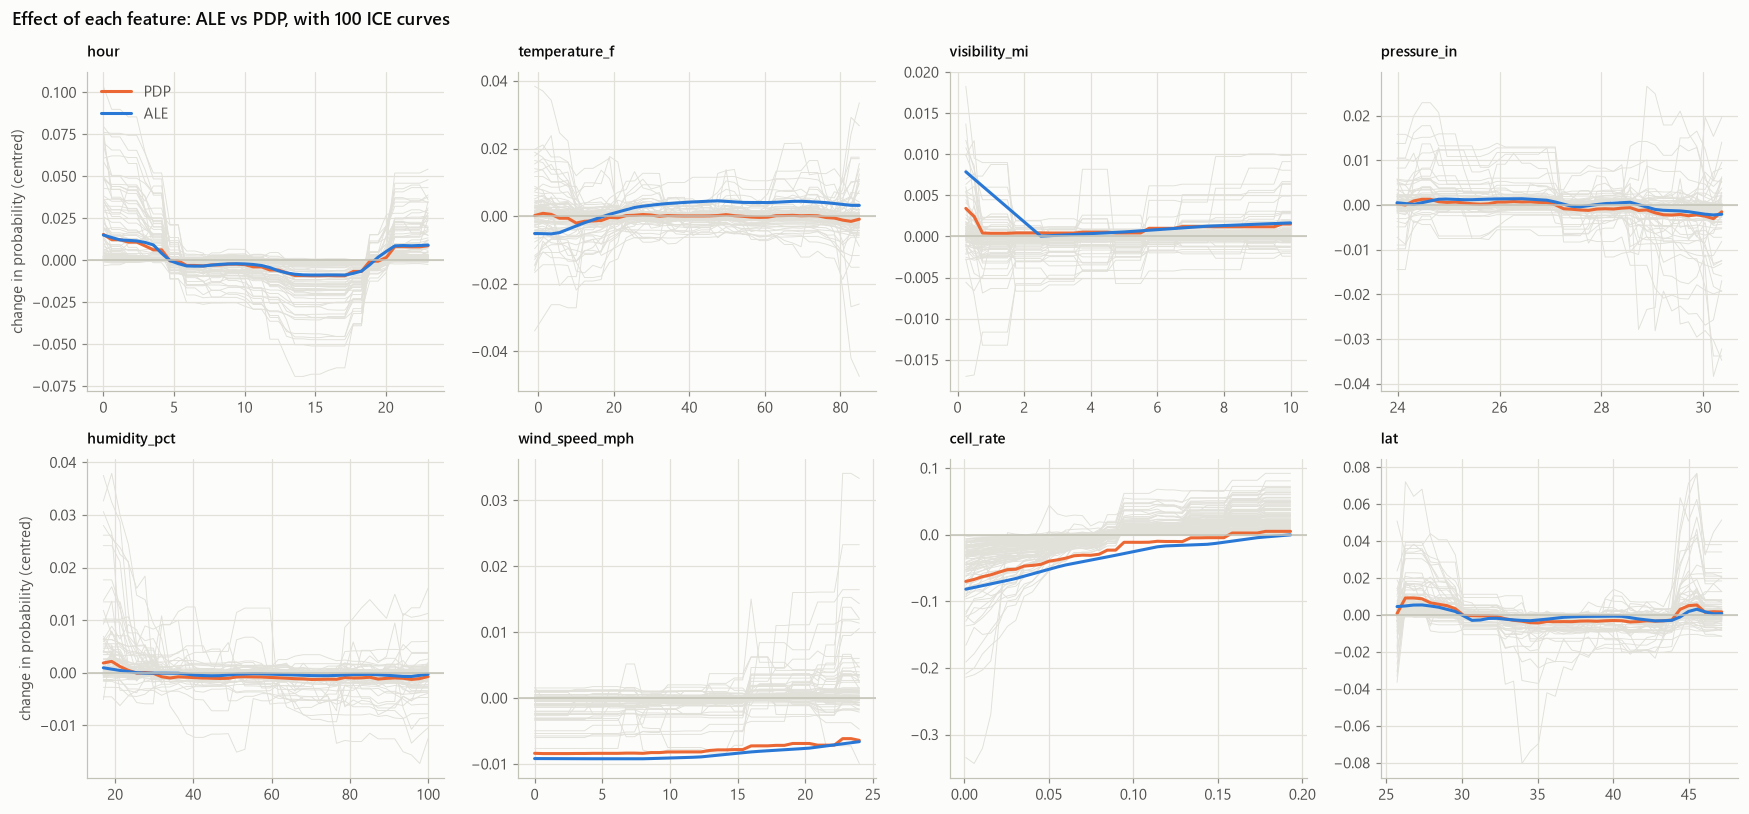

In [4]:
effect_features = [
    "hour",
    "temperature_f",
    "visibility_mi",
    "pressure_in",
    "humidity_pct",
    "wind_speed_mph",
    "cell_rate",
    "lat",
]
observed = x_sample.dropna().reset_index(drop=True)
print(f"{len(observed):,} of {len(x_sample):,} sampled rows have every reading")
schema = effector.Schema(
    feature_names=list(observed.columns),
    feature_types=[
        "nominal" if isinstance(observed[c].dtype, pd.CategoricalDtype) else "continuous"
        for c in observed.columns
    ],
    # A code-to-name mapping, because a sample need not contain every category.
    category_names=[
        dict(enumerate(observed[c].cat.categories))
        if isinstance(observed[c].dtype, pd.CategoricalDtype)
        else None
        for c in observed.columns
    ],
)
matrix = explain.numeric_matrix(observed)


def matrix_predict(values: np.ndarray) -> np.ndarray:
    return predict(explain.table_from_matrix(values, observed))


positions = [list(observed.columns).index(f) for f in effect_features]
ale = effector.ALE(
    matrix, matrix_predict, schema=schema, nof_instances=5000, random_state=config.SEED
)
ale.fit(features=positions)
pdp = effector.PDP(
    matrix, matrix_predict, schema=schema, nof_instances=2000, random_state=config.SEED
)
pdp.fit(features=positions)
ice_rows = matrix[rng.choice(len(matrix), 100, replace=False)]

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
ale_curves = {}
for ax, name, position in zip(axes.flat, effect_features, positions, strict=True):
    values = observed[name].dropna()
    grid = np.linspace(values.quantile(0.01), values.quantile(0.99), 40)
    for row in ice_rows:
        repeated = np.repeat(row[None, :], len(grid), axis=0)
        repeated[:, position] = grid
        curve = matrix_predict(repeated)
        ax.plot(grid, curve - curve.mean(), color=plots.GRID, linewidth=0.6)
    pdp_curve = pdp.eval(position, grid)
    ale_curve = ale.eval(position, grid)
    ale_curves[name] = {"x": grid.round(4).tolist(), "effect": np.round(ale_curve, 6).tolist()}
    ax.plot(grid, pdp_curve, color=plots.SERIES[1], label="PDP")
    ax.plot(grid, ale_curve, color=plots.SERIES[0], label="ALE")
    ax.axhline(0, color=plots.BASELINE, linewidth=1)
    ax.set_title(name, fontsize=10)
axes[0, 0].set_ylabel("change in probability (centred)")
axes[1, 0].set_ylabel("change in probability (centred)")
axes[0, 0].legend(loc="upper left")
fig.suptitle(
    "Effect of each feature: ALE vs PDP, with 100 ICE curves",
    x=0.01,
    ha="left",
    fontweight="semibold",
)
plt.tight_layout()
plt.show()

### Regional effects: is a global curve averaging away opposite effects?

effector searches for sub-populations (split on other features) in which a feature's
local effects are more alike. A split is reported here only if it removes at least 10%
of the effect's heterogeneity.

hour: splitting removes 0% of heterogeneity
temperature_f: splitting removes 0% of heterogeneity


cell_rate: splitting removes 25% of heterogeneity
cell_rate
├─ road_class = interstate                                      n = 564
└─ road_class ∈ {us_route, state_route, other_highway, local}
   ├─ state = CA                                                n = 375
   └─ state ∈ {AL, AR, AZ, …} (40 levels)                       n = 1,061


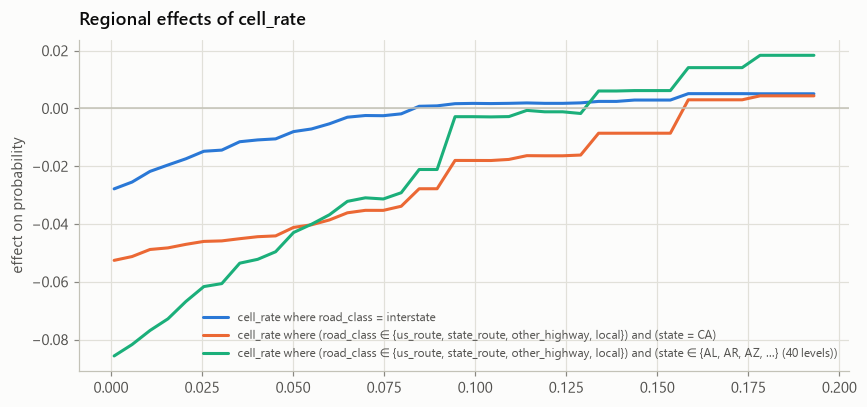

In [5]:
regional = {}
for name in ("hour", "temperature_f", "cell_rate"):
    position = list(observed.columns).index(name)
    partition = pdp.find_regions(position)
    root = partition.regions[0]
    leaves = partition.leaves
    leaf_heter = sum(leaf.weight * leaf.heterogeneity for leaf in leaves)
    drop = 1 - leaf_heter / root.heterogeneity if root.heterogeneity else 0.0
    regional[name] = {
        "heterogeneity_drop": float(drop),
        "tree": partition.tree_lines() if drop >= 0.10 else [],
    }
    print(f"{name}: splitting removes {drop:.0%} of heterogeneity")
    if drop >= 0.10:
        print("\n".join(partition.tree_lines()))
        grid = np.linspace(observed[name].quantile(0.01), observed[name].quantile(0.99), 40)
        fig, ax = plt.subplots(figsize=(8, 3.8))
        for i, leaf in enumerate(leaves[:3]):
            ax.plot(
                grid,
                partition.eval(leaf.idx, grid),
                color=plots.SERIES[i],
                label=partition.label(leaf.idx),
            )
        ax.axhline(0, color=plots.BASELINE, linewidth=1)
        ax.set_title(f"Regional effects of {name}")
        ax.set_ylabel("effect on probability")
        ax.legend(loc="best", fontsize=8)
        plt.tight_layout()
        plt.show()

## 3 · Interactions: which features act together?

For each pair among the ten most important features, Friedman's H statistic measures how
much of the pair's joint partial dependence is left after their two separate effects, in
log-odds, over 500 test accidents. It needs only the model's predictions, so it is exact
for categorical features such as state and weather. SHAP interaction values were the first
plan, but for LightGBM they come from a parser that misreads categorical splits: in a check
their sums missed LightGBM's own exact contributions by up to 0.86 log-odds, so they are
not used. The EBM learned its own pairwise terms, a second, independent view.

H statistic (log-odds)
state      road_class                  0.1471
cell_rate  state                       0.1265
cell_count hour                        0.1263
state      lat                         0.1081
           cell_count                  0.1035
cell_rate  road_class                  0.1030
           cell_count                  0.0859
cell_count road_class                  0.0702
state      hour                        0.0664
cell_rate  junction                    0.0592

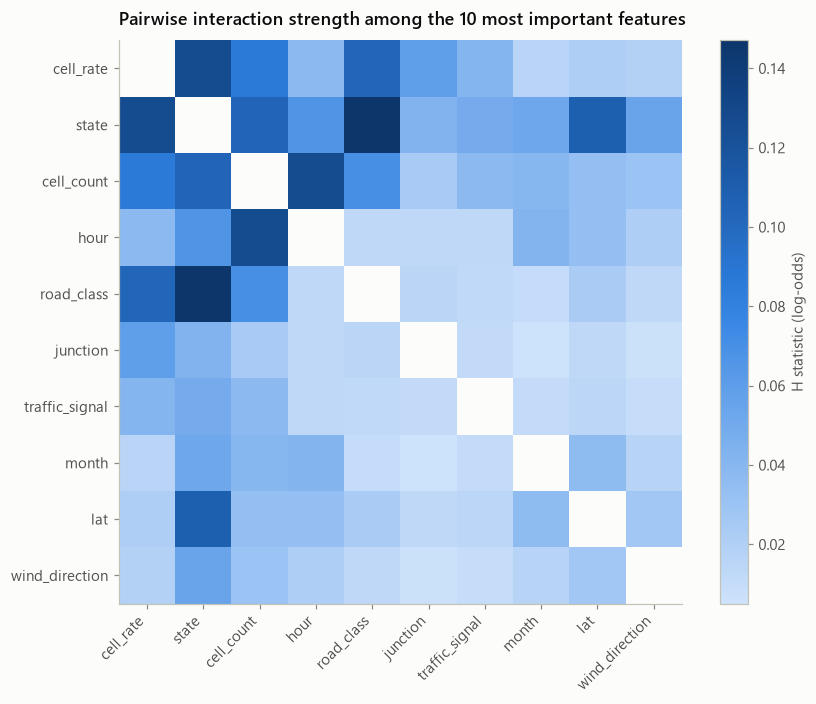

EBM's strongest learned pairs:


,EBM term importance
cell_rate & road_class,0.1998
lat & road_class,0.1706
lng & cell_count,0.1583
hour & cell_count,0.1545
state & road_class,0.1350
lng & road_class,0.1275
cell_count & road_class,0.1022
hour & month,0.0992
lat & traffic_signal,0.0511
pressure_in & road_class,0.0343


In [6]:
def margin(frame: pd.DataFrame) -> np.ndarray:
    """The model's log-odds before calibration, the scale of the SHAP values."""
    x, _ = benchmark.prepare(spec, frame.assign(y=0), medians)
    return calibrate.logit(model.predict_proba(x)[:, 1])


inter_rows = x_sample.head(500)
top_features = list(shap_importance.head(10).index)
strength = explain.interaction_strength(margin, inter_rows, top_features)
pairs = (
    strength.where(np.triu(np.ones(strength.shape, dtype=bool), 1))
    .stack()
    .sort_values(ascending=False)
    .head(10)
)
display(pairs.rename("H statistic (log-odds)").round(4).to_frame())

fig, ax = plt.subplots(figsize=(8, 6.5))
# the diagonal is not an interaction; leaving it blank keeps the scale for real pairs
image = ax.imshow(strength.mask(np.eye(len(strength), dtype=bool)), cmap=plots.SEQUENTIAL)
ax.set_xticks(range(len(top_features)), top_features, rotation=45, ha="right")
ax.set_yticks(range(len(top_features)), top_features)
ax.set_title("Pairwise interaction strength among the 10 most important features")
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.046, label="H statistic (log-odds)")
plt.tight_layout()
plt.show()

if ebm_file.exists():
    ebm_pairs = terms[[t for t in terms.index if " & " in t]].sort_values(ascending=False).head(10)
    print("EBM's strongest learned pairs:")
    display(ebm_pairs.round(4).to_frame("EBM term importance"))

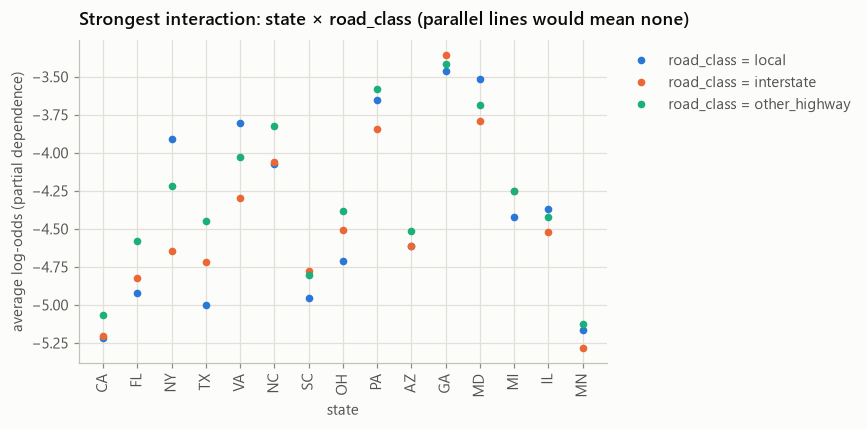

In [7]:
def grid_values(column: pd.Series, size: int) -> list:
    """Values to evaluate a feature at: its commonest categories, or an even grid."""
    if isinstance(column.dtype, pd.CategoricalDtype):
        return list(column.value_counts().head(size).index)
    low, high = column.quantile([0.02, 0.98], interpolation="nearest")
    values = np.linspace(low, high, size)
    if pd.api.types.is_integer_dtype(column):
        values = np.unique(values.round())
    return list(values)


def levels(column: pd.Series) -> list:
    """Three values to hold a feature at: commonest categories, or 10th/50th/90th centiles."""
    if isinstance(column.dtype, pd.CategoricalDtype) or column.nunique() <= 5:
        return list(column.value_counts().head(3).index)
    return sorted(set(column.quantile([0.1, 0.5, 0.9], interpolation="nearest")))


def with_value(frame: pd.DataFrame, column: str, value) -> pd.DataFrame:
    """Set one column to a single value in every row, keeping the column's type."""
    out = frame.copy()
    out[column] = pd.Series(value, index=frame.index).astype(frame[column].dtype)
    return out


a, b = pairs.index[0]
categorical_a = isinstance(inter_rows[a].dtype, pd.CategoricalDtype)
grid_a = grid_values(inter_rows[a], 15 if categorical_a else 25)
x_positions = [str(v) for v in grid_a] if categorical_a else grid_a
fig, ax = plt.subplots(figsize=(8, 4))
for i, level in enumerate(levels(inter_rows[b])):
    held = with_value(inter_rows, b, level)
    curve = [margin(with_value(held, a, value)).mean() for value in grid_a]
    style = "o" if categorical_a else "o-"  # categories have no order to join with lines
    ax.plot(x_positions, curve, style, color=plots.SERIES[i], markersize=4, label=f"{b} = {level}")
ax.set_xlabel(a)
ax.set_ylabel("average log-odds (partial dependence)")
ax.set_title(f"Strongest interaction: {a} × {b} (parallel lines would mean none)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
if categorical_a:
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

## 4 · Where and when the model sees risk

Left: the summed contribution of the place features (latitude, longitude, state, the cell's
history) per hexagon, in log-odds; red raises risk, blue lowers it. Right: the observed
Severity-4 rate in test months. **Caveat (notebook 02):** much of the place signal reflects
how each state's agencies report closures, not only how dangerous the roads are.

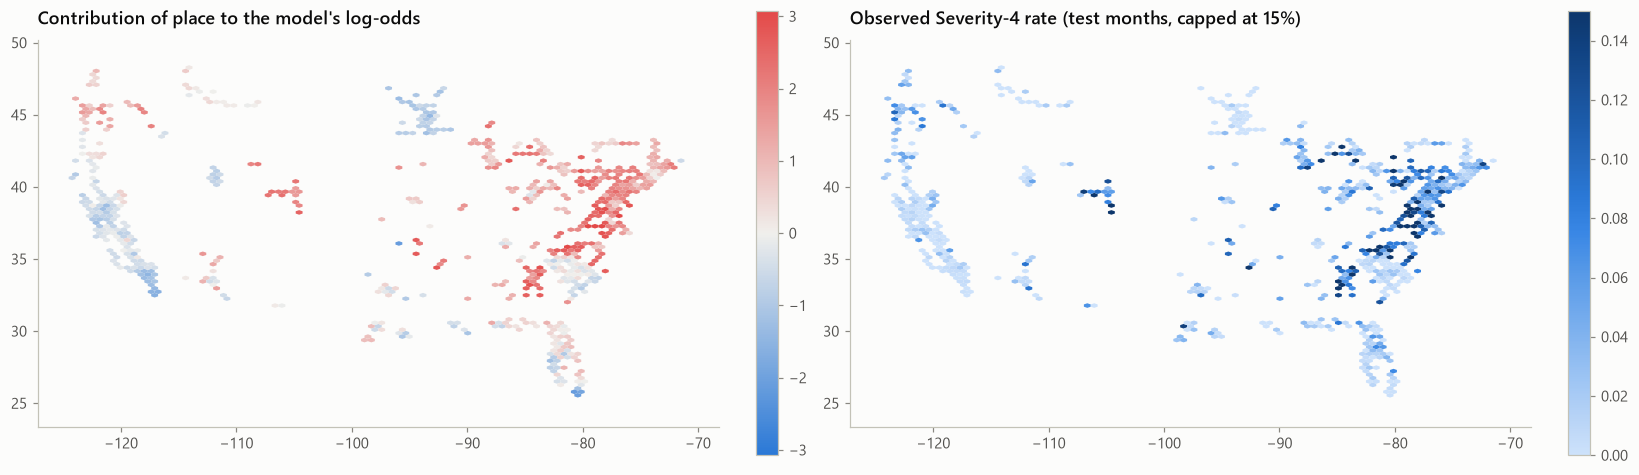

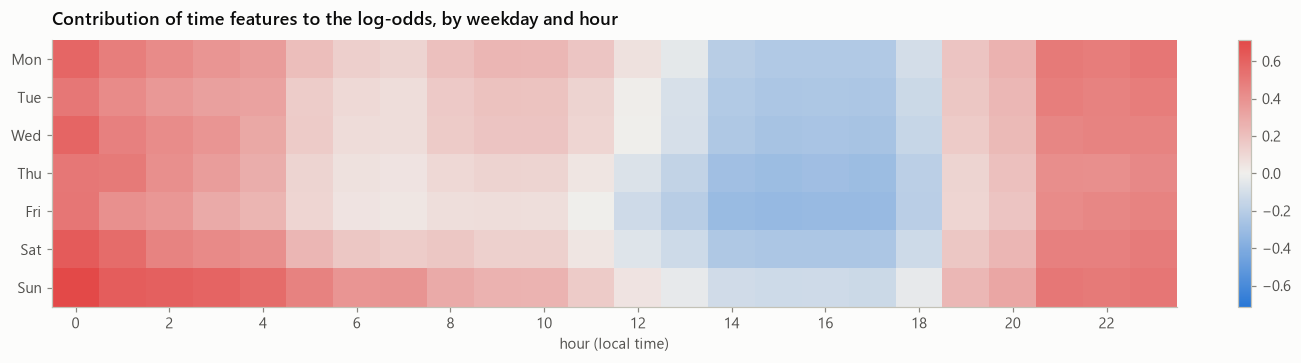

In [8]:
map_rows = test.sample(150_000, random_state=config.SEED + 2).reset_index(drop=True)
map_contrib, _ = explain.tree_contributions(model, map_rows[features.FEATURES])
place = explain.family_contributions(map_contrib)["place"]
limit = float(np.quantile(np.abs(place), 0.98))
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8))
hb = left.hexbin(
    map_rows["lng"],
    map_rows["lat"],
    C=place,
    reduce_C_function=np.mean,
    gridsize=90,
    mincnt=30,
    cmap=plots.DIVERGING,
    vmin=-limit,
    vmax=limit,
    linewidths=0,
)
left.set_title("Contribution of place to the model's log-odds")
fig.colorbar(hb, ax=left, fraction=0.03)
hb = right.hexbin(
    map_rows["lng"],
    map_rows["lat"],
    C=map_rows["y"],
    reduce_C_function=np.mean,
    gridsize=90,
    mincnt=30,
    cmap=plots.SEQUENTIAL,
    vmax=0.15,
    linewidths=0,
)
right.set_title("Observed Severity-4 rate (test months, capped at 15%)")
fig.colorbar(hb, ax=right, fraction=0.03)
for ax in (left, right):
    ax.set_aspect(1.25)
    ax.grid(False)
plt.tight_layout()
plt.show()

time_part = explain.family_contributions(map_contrib)["time"]
grid = time_part.groupby([map_rows["weekday"], map_rows["hour"]]).mean().unstack()
limit = float(np.abs(grid.to_numpy()).max())
fig, ax = plt.subplots(figsize=(12, 3.4))
image = ax.imshow(grid, aspect="auto", cmap=plots.DIVERGING, vmin=-limit, vmax=limit)
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour (local time)")
ax.set_title("Contribution of time features to the log-odds, by weekday and hour")
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.03)
plt.tight_layout()
plt.show()

## 5 · Single accidents: why this score, and what would change it?

Four accidents chosen by rule, not by hand, at the decision threshold for a 20 : 1 cost of
a missed major impact against a false alarm (p > 1/21): the median true positive, the false
positive with the highest score, the missed accident with the lowest score, and the true
negative closest below the threshold. Bars show each feature's push in log-odds from the
model's base value.

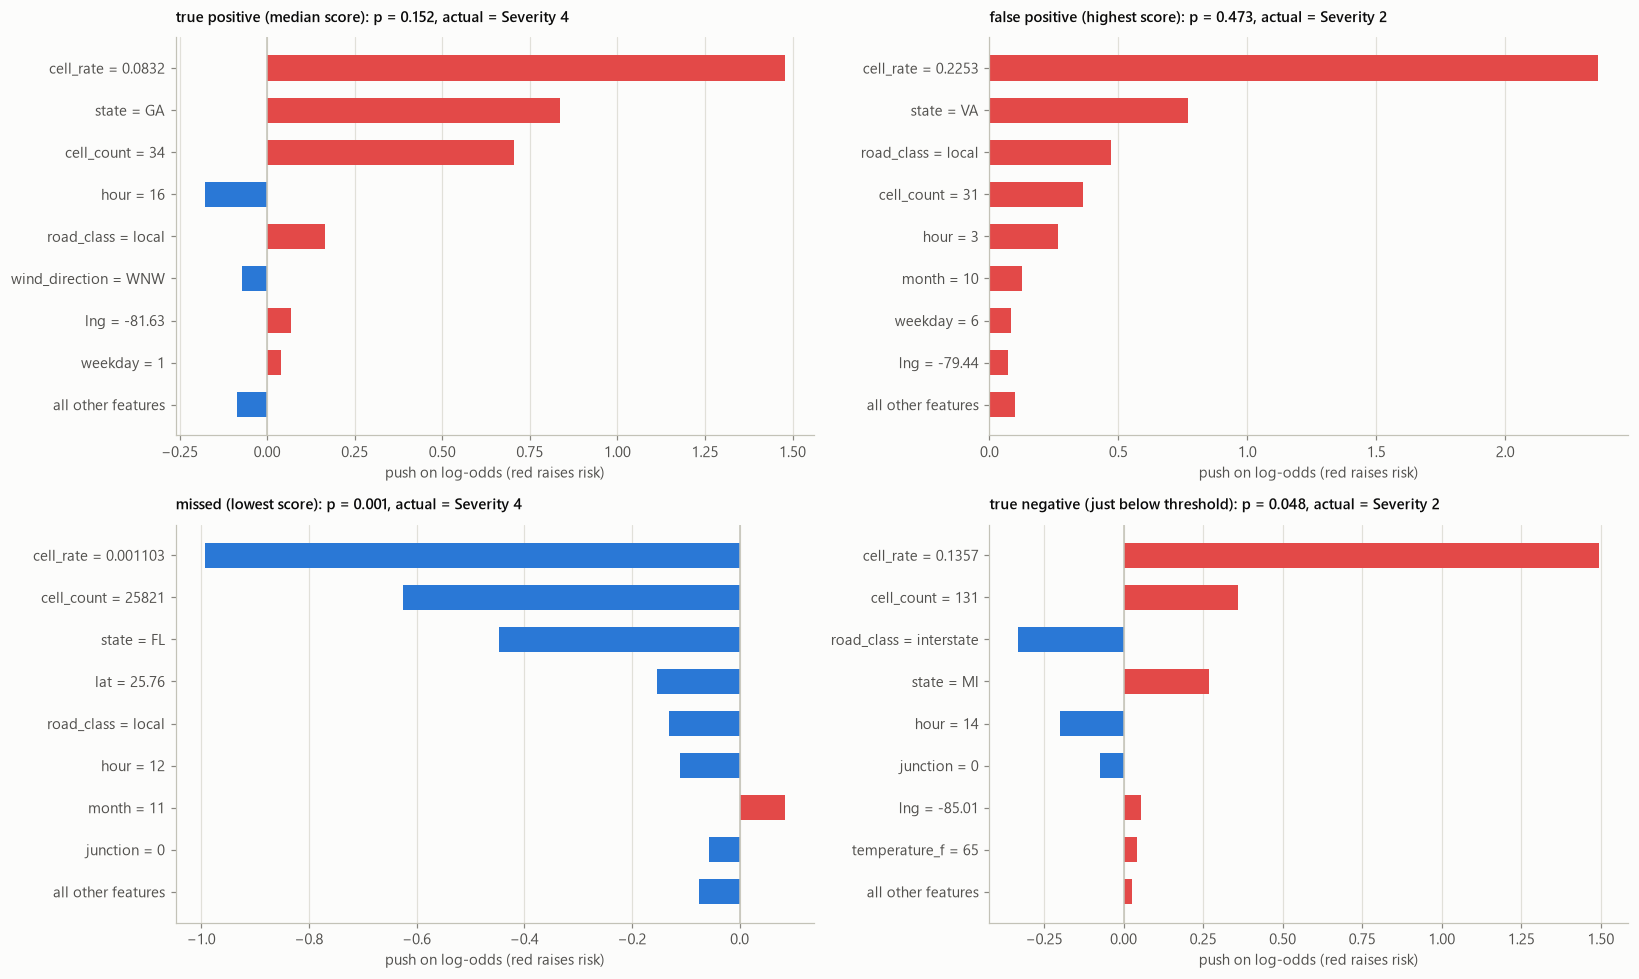

In [9]:
threshold = calibrate.cost_threshold(20)
p_sample = predict(sample)
y_sample = sample["y"].to_numpy()
flag = p_sample >= threshold
cases = {}
tp = np.flatnonzero(flag & (y_sample == 1))
cases["true positive (median score)"] = tp[np.argsort(p_sample[tp])[len(tp) // 2]]
fp = np.flatnonzero(flag & (y_sample == 0))
cases["false positive (highest score)"] = fp[np.argmax(p_sample[fp])]
fn = np.flatnonzero(~flag & (y_sample == 1))
cases["missed (lowest score)"] = fn[np.argmin(p_sample[fn])]
tn = np.flatnonzero(~flag & (y_sample == 0))
cases["true negative (just below threshold)"] = tn[np.argmax(p_sample[tn])]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
local = {}
for ax, (label, row) in zip(axes.flat, cases.items(), strict=True):
    values = contributions.iloc[row]
    top = values.reindex(values.abs().sort_values(ascending=False).index[:8])
    other = values.drop(top.index).sum()
    parts = pd.concat([top, pd.Series({"all other features": other})])[::-1]
    shown = []
    for f in parts.index:
        value = x_sample.iloc[row][f] if f in x_sample else None
        if value is None:
            shown.append(f)
        elif isinstance(value, float):
            shown.append(f"{f} = {value:.4g}")
        else:
            shown.append(f"{f} = {value}")
    ax.barh(
        shown,
        parts.values,
        height=0.6,
        color=[plots.RED_ARM if v > 0 else plots.BLUE_ARM for v in parts.values],
    )
    ax.axvline(0, color=plots.BASELINE, linewidth=1)
    ax.set_title(
        f"{label}: p = {p_sample[row]:.3f}, actual = Severity {4 if y_sample[row] else 2}",
        fontsize=10,
    )
    ax.set_xlabel("push on log-odds (red raises risk)")
    ax.grid(axis="y", visible=False)
    local[label] = {
        "p": float(p_sample[row]),
        "y": int(y_sample[row]),
        "contributions": top.round(4).to_dict(),
    }
plt.tight_layout()
plt.show()

### Counterfactuals: the smallest change in time and weather that crosses the threshold

DiCE searches for diverse, nearby versions of an accident that land on the other side of
the threshold, changing only what could plausibly have been different at the same place:
the hour and the weather. Each suggestion is re-scored with the real model and kept only
if it truly crosses the threshold.

In [10]:
vary = [
    "hour",
    "temperature_f",
    "visibility_mi",
    "precipitation_in",
    "wind_speed_mph",
    "humidity_pct",
    "weather",
]
continuous = [c for c in features.NUMERIC_FEATURES]
dice_frame = train.sample(50_000, random_state=config.SEED)[features.FEATURES + ["y"]].copy()
for name in features.NUMERIC_FEATURES:
    dice_frame[name] = dice_frame[name].fillna(dice_frame[name].median())
for name in features.CATEGORICAL_FEATURES:
    dice_frame[name] = dice_frame[name].astype(str)


class ThresholdedModel:
    """DiCE passes text columns and decides at 0.5 (it overrides lower thresholds), so the
    scores are shifted on the log-odds scale: they pass 0.5 exactly where the calibrated
    probability passes the decision threshold."""

    def predict_proba(self, frame: pd.DataFrame) -> np.ndarray:
        p = predict(explain.table_from_strings(frame, x_sample))
        shifted = 1 / (1 + np.exp(-(calibrate.logit(p) - calibrate.logit(np.array(threshold)))))
        return np.column_stack([1 - shifted, shifted])


dice_data = dice_ml.Data(dataframe=dice_frame, continuous_features=continuous, outcome_name="y")
dice = dice_ml.Dice(
    dice_data, dice_ml.Model(model=ThresholdedModel(), backend="sklearn"), method="random"
)
ranges = {
    "hour": [0, 23],
    "temperature_f": [-10, 105],
    "visibility_mi": [0, 10],
    "precipitation_in": [0, 0.3],
    "wind_speed_mph": [0, 40],
    "humidity_pct": [5, 100],
}
counterfactuals = {}
for label, desired in (
    ("true positive (median score)", 0),
    ("true negative (just below threshold)", 1),
):
    row = cases[label]
    query = x_sample.iloc[[row]].copy()
    for name in features.NUMERIC_FEATURES:
        query[name] = query[name].fillna(dice_frame[name].median())
    query = query.astype({n: str for n in features.CATEGORICAL_FEATURES})
    try:
        result = dice.generate_counterfactuals(
            query,
            total_CFs=6,
            desired_class=desired,
            features_to_vary=vary,
            permitted_range=ranges,
            random_seed=config.SEED,
        )
        found = result.cf_examples_list[0].final_cfs_df
    except UserConfigValidationException:  # DiCE raises when it finds none
        found = None
    if found is None or found.empty:
        print(f"{label}: no counterfactual found")
        continue
    found = found.drop(columns="y")
    found["p"] = predict(explain.table_from_strings(found, x_sample))
    crosses = found["p"] < threshold if desired == 0 else found["p"] >= threshold
    found = found[crosses]
    changed = [c for c in vary if (found[c].astype(str) != query.iloc[0][c].__str__()).any()]
    print(
        f"{label}: original p = {p_sample[row]:.3f}; {len(found)} verified counterfactuals, "
        f"changing {', '.join(changed) or 'nothing'}"
    )
    display(
        pd.concat(
            [
                query[vary].assign(p=p_sample[row]).rename(index=lambda _: "original"),
                found[vary + ["p"]],
            ]
        )
    )
    counterfactuals[label] = found[vary + ["p"]].head(3).to_dict("records")

No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 00 sec
true positive (median score): no counterfactual found


true negative (just below threshold): original p = 0.048; 6 verified counterfactuals, changing hour, temperature_f, wind_speed_mph, humidity_pct, weather


,hour,temperature_f,visibility_mi,precipitation_in,wind_speed_mph,humidity_pct,weather,p
original,14,65.0,10.0,0.0,3.0,34.0,cloudy,0.047610
0,14,65.0,10.0,0.0,30.3,34.0,cloudy,0.052294
1,4,65.0,10.0,0.0,3.0,39.2,cloudy,0.080512
2,14,54.3,10.0,0.0,3.0,34.0,cloudy,0.048307
3,13,65.0,10.0,0.0,3.0,54.5,cloudy,0.054449
4,14,74.3,10.0,0.0,29.4,34.0,cloudy,0.050442
5,23,65.0,10.0,0.0,3.0,34.0,snow_ice,0.073339


## 6 · Can these explanations be trusted?

### a · Stability across refits

The chosen configuration is refitted five times on different 400k-row bootstrap samples
of the training months. If the importance ranking changed a lot between refits, it would
describe noise rather than the data.

Kendall's τ between refits: mean 0.924, min 0.891


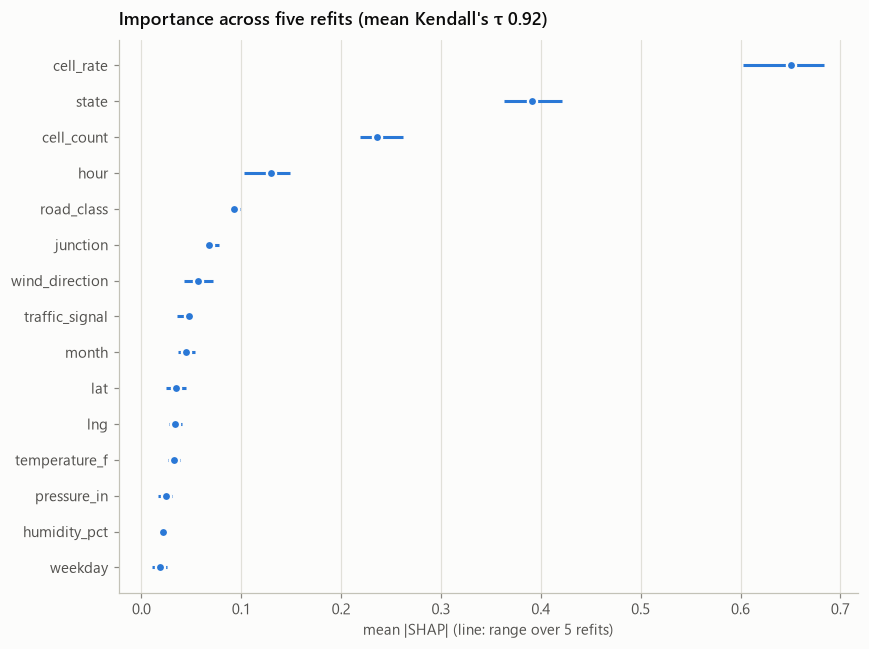

In [11]:
data = benchmark.load_splits()
stop_x, stop_y = benchmark.prepare(spec, data["stop"], medians)
stability_rows = x_sample.head(10_000)
refit_importance = {}
for seed in range(5):
    boot = data["fit"].sample(400_000, replace=True, random_state=seed)
    bx, by = benchmark.prepare(spec, boot, medians)
    refit = spec.fit(frozen["params"], bx, by, stop_x, stop_y)
    refit_contrib, _ = explain.tree_contributions(refit, stability_rows)
    refit_importance[f"refit {seed + 1}"] = explain.mean_absolute(refit_contrib)
stability = pd.DataFrame(refit_importance)
taus = explain.rank_agreement(refit_importance).to_numpy()
off_diagonal = taus[~np.eye(len(taus), dtype=bool)]
print(f"Kendall's τ between refits: mean {off_diagonal.mean():.3f}, min {off_diagonal.min():.3f}")

top = stability.mean(axis=1).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(len(top))
ax.hlines(
    yy,
    stability.loc[top.index].min(axis=1),
    stability.loc[top.index].max(axis=1),
    color=plots.SERIES[0],
    linewidth=2,
)
ax.plot(
    top.values, yy, "o", color=plots.SERIES[0], markeredgecolor=plots.SURFACE, markeredgewidth=1.5
)
ax.set_yticks(yy, top.index)
ax.set_xlabel("mean |SHAP| (line: range over 5 refits)")
ax.set_title(f"Importance across five refits (mean Kendall's τ {off_diagonal.mean():.2f})")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### b · Faithfulness: do the top attributions point at what the model really uses?

For the 1,000 highest-scored test accidents, replace each accident's k most
risk-raising features (by SHAP) with typical values, and compare with replacing k random
features. Faithful attributions make the score fall much faster.

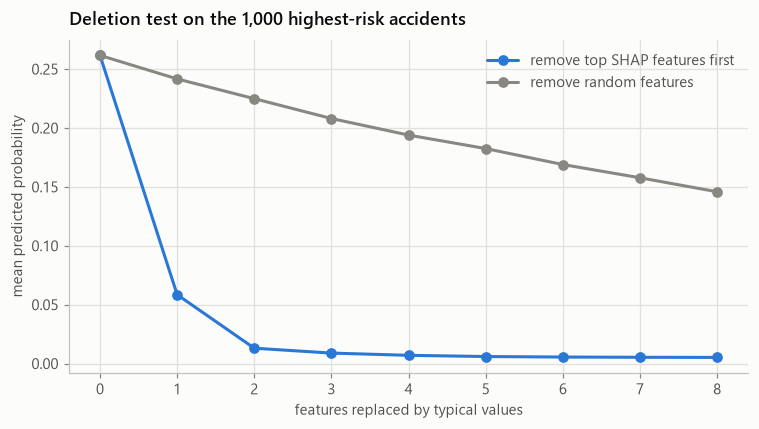

,top attributions,random features
features removed,,
0,0.2616,0.2616
1,0.0585,0.2417
2,0.0130,0.2249
3,0.0089,0.2080
4,0.0070,0.1940
5,0.0060,0.1825
6,0.0055,0.1690
7,0.0053,0.1577
8,0.0052,0.1459


In [12]:
high = np.argsort(-p_sample)[:1000]
deletion = explain.deletion_test(
    predict,
    x_sample.iloc[high].reset_index(drop=True),
    contributions.iloc[high].reset_index(drop=True),
    explain.reference_values(x_sample),
    steps=8,
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    deletion.index,
    deletion["top attributions"],
    "o-",
    color=plots.SERIES[0],
    label="remove top SHAP features first",
)
ax.plot(
    deletion.index,
    deletion["random features"],
    "o-",
    color=plots.MUTED,
    label="remove random features",
)
ax.set_xlabel("features replaced by typical values")
ax.set_ylabel("mean predicted probability")
ax.set_title("Deletion test on the 1,000 highest-risk accidents")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
display(deletion.round(4))

### c · Agreement with a glass-box model

The EBM is additive by construction, so its shape functions are exact explanations of
itself. If the chosen model's average SHAP curve for a feature has the same shape as the
EBM's term, two very different model families learned the same relationship.

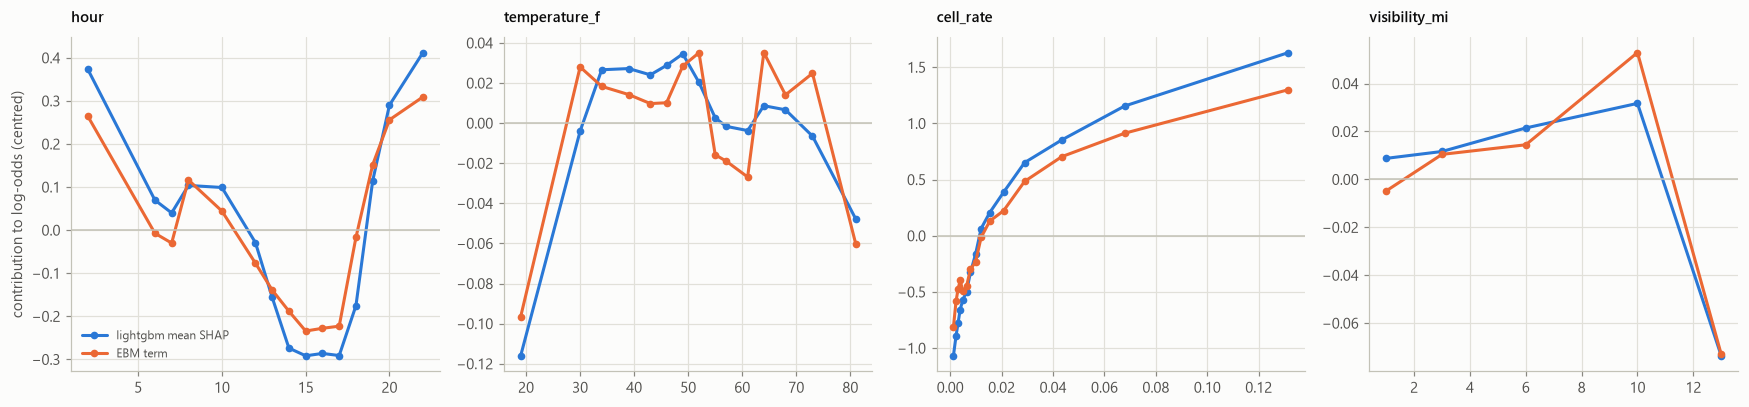

In [13]:
if ebm_file.exists():
    ebm_terms = pd.DataFrame(ebm.eval_terms(x_sample), columns=ebm.term_names_)
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
    for ax, name in zip(axes, ["hour", "temperature_f", "cell_rate", "visibility_mi"], strict=True):
        bins = pd.qcut(x_sample[name], 15, duplicates="drop")
        centres = x_sample.groupby(bins, observed=True)[name].median()
        gbdt = contributions[name].groupby(bins, observed=True).mean()
        glass = ebm_terms[name].groupby(bins, observed=True).mean()
        ax.plot(
            centres,
            gbdt - gbdt.mean(),
            "o-",
            color=plots.SERIES[0],
            markersize=4,
            label=f"{chosen} mean SHAP",
        )
        ax.plot(
            centres,
            glass - glass.mean(),
            "o-",
            color=plots.SERIES[1],
            markersize=4,
            label="EBM term",
        )
        ax.axhline(0, color=plots.BASELINE, linewidth=1)
        ax.set_title(name, fontsize=10)
    axes[0].set_ylabel("contribution to log-odds (centred)")
    axes[0].legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()

## 7 · Where the model fails

Missed major-impact accidents (false negatives) compared with caught ones (true
positives) at the 20 : 1 threshold, as standardised mean differences: how many standard
deviations the missed group sits from the caught group on each feature.

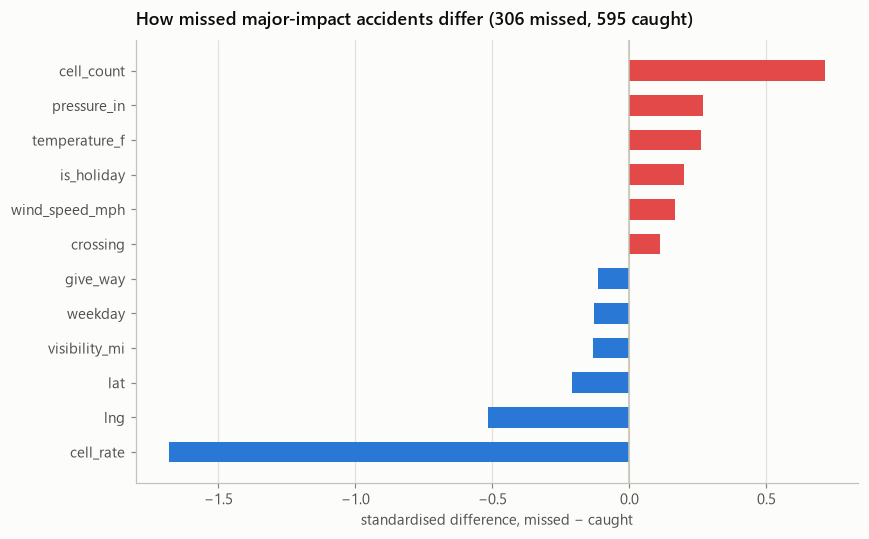

,missed,caught,difference
state,,,
VA,0.075,0.188,-0.113
GA,0.036,0.131,-0.095
NC,0.016,0.103,-0.086
TX,0.078,0.027,0.052
CA,0.108,0.000,0.108
FL,0.137,0.008,0.129


,missed,caught,difference
road_class,,,
local,0.297,0.487,-0.190
us_route,0.026,0.079,-0.053
state_route,0.147,0.143,0.004
other_highway,0.173,0.151,0.022
interstate,0.356,0.139,0.217


,missed,caught,difference
weather,,,
clear,0.412,0.444,-0.032
unknown,0.016,0.035,-0.019
storm,0.000,0.007,-0.007
fog_obscured,0.042,0.032,0.011
snow_ice,0.082,0.064,0.018
cloudy,0.363,0.339,0.023


In [14]:
caught = sample[flag & (y_sample == 1)]
missed = sample[~flag & (y_sample == 1)]
smd = {}
for name in features.NUMERIC_FEATURES:
    pooled = np.sqrt((caught[name].var() + missed[name].var()) / 2)
    if pooled and np.isfinite(pooled):
        smd[name] = (missed[name].mean() - caught[name].mean()) / pooled
smd = pd.Series(smd).sort_values()
shown = pd.concat([smd.head(6), smd.tail(6)])
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    shown.index,
    shown.values,
    height=0.6,
    color=[plots.RED_ARM if v > 0 else plots.BLUE_ARM for v in shown.values],
)
ax.axvline(0, color=plots.BASELINE, linewidth=1)
ax.set_xlabel("standardised difference, missed − caught")
ax.set_title(
    f"How missed major-impact accidents differ ({len(missed):,} missed, {len(caught):,} caught)"
)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
for name in ("state", "road_class", "weather"):
    shares = pd.DataFrame(
        {
            "missed": missed[name].astype(str).value_counts(normalize=True),
            "caught": caught[name].astype(str).value_counts(normalize=True),
        }
    ).fillna(0)
    shares["difference"] = shares["missed"] - shares["caught"]
    ordered = shares.sort_values("difference")
    if len(ordered) > 6:  # the three groups most under- and most over-represented
        ordered = pd.concat([ordered.head(3), ordered.tail(3)])
    display(ordered.round(3))

## 8 · Saved for the dashboard

Global importance, families, effect curves, interaction pairs, the time heatmap,
reliability results and the rule-chosen local cases go to
`data/processed/final/explanations.json`; notebook 08 packages them.

In [15]:
explanations = {
    "model": chosen,
    "base_value": base_value,
    "importance": shap_importance.round(5).to_dict(),
    "permutation": permutation["ap_drop"].round(5).to_dict(),
    "families": family_share.round(4).to_dict(),
    "agreement": agreement.round(3).to_dict(),
    "ale": ale_curves,
    "regional": regional,
    "interactions": [
        {"a": a_, "b": b_, "strength": round(float(v), 5)} for (a_, b_), v in pairs.items()
    ],
    "time_heatmap": grid.round(4).to_numpy().tolist(),
    "stability_tau_mean": float(off_diagonal.mean()),
    "deletion": deletion.round(5).reset_index().to_dict("records"),
    "local_cases": local,
    "counterfactuals": counterfactuals,
}  # fmt: skip
(FINAL / "explanations.json").write_text(json.dumps(explanations, indent=2, default=str))
print("saved", FINAL / "explanations.json")

saved data\processed\final\explanations.json


## 9 · Limits of these explanations

- **Associations, not causes.** The model learned which conditions co-occur with
  Severity-4 *reports*. A feature with a large attribution is a good predictor, not
  necessarily a cause; changing it in the world need not change the outcome.
- **Place carries reporting practice.** States and agencies differ in when they report a
  closure (notebook 02), so the place features partly measure reporting, not danger.
- **Pressure carries altitude.** Station pressure falls with elevation, so its effect is
  partly a location effect.
- **Season effects rest on one to two years** of training months; the `month` effect
  should not be read as a stable seasonal law.
- **SHAP values are in log-odds**; the dashboard converts to probabilities for display.

## Decisions and evidence

_Written from the outputs above._

1. **Place dominates.** Place features carry 67% of the total absolute attribution on
   30,000 test accidents, time 14%, road 13% and weather 6%. The area's past rate of
   major-impact reports alone averages 0.65 log-odds, then state (0.43), the area's past
   report count (0.24) and hour (0.20).
2. **The ranking is a property of the data, not of one model.** Mean |SHAP| rankings agree
   across LightGBM, XGBoost, CatBoost and the glass-box EBM (Kendall's τ 0.85–0.93), and
   across five bootstrap refits (mean τ 0.92, minimum 0.89). Permutation importance agrees
   on the leaders (area rate, state, road class, area count, hour) but ranks the long tail
   by noise, since most features change test AP by less than 0.001; hence its overall τ
   with SHAP is only 0.41.
3. **Effect shapes.** The hour effect is U-shaped: about +1.5 percentage points around
   midnight against −0.9 at 17:00 (ALE, centred), and the EBM's hour term traces the same
   curve. Risk rises steeply with the area's past rate and then flattens. Weather effects
   are small, under one percentage point across the observed range. ALE and PDP agree for
   hour, humidity, pressure and latitude but part for temperature (ALE about −0.5 points
   near freezing, PDP flat) and for visibility under a mile (ALE +0.8, PDP +0.3). That is
   the pattern expected when PDP's forced combinations, such as freezing temperatures in
   summer rows, dilute an effect that ALE measures within real accidents.
4. **One global curve hides a split.** For the area's past rate, splitting by road class
   and state removes 25% of the heterogeneity: on interstates the effect is much flatter
   than on other roads, and California differs from the remaining states. No split helps
   for hour or temperature (0%).
5. **Interactions point back at reporting practice.** The strongest pairs by Friedman's H
   are state × road class (0.15 log-odds), area rate × state (0.13) and area count × hour
   (0.13). The EBM, fitted independently, also ranks area rate × road class, hour × area
   count and state × road class among its strongest pairs.
6. **Single cases are dominated by place.** The median caught accident (p = 0.15) owes most
   of its score to its area's past rate (+1.5 log-odds) and state; no plausible change in
   hour or weather takes it below the 20 : 1 threshold. The lowest-scored missed accident
   (p = 0.001) happened in a Miami area with 25,821 past reports and a 0.1% past rate: the
   model cannot see a rare major event in a place that seldom reports one.
7. **The attributions are faithful.** For the 1,000 highest-scored test accidents,
   replacing each accident's single top SHAP feature with a typical value cuts the mean
   predicted probability from 0.262 to 0.059; replacing a random feature leaves 0.242.
   After three replacements the figures are 0.009 and 0.208.
8. **Failures are structural.** Missed major-impact accidents sit in areas with a much
   lower past rate than caught ones (standardised difference −1.7) and more past reports
   (+0.7); 36% are on interstates against 14% of caught ones, and Florida and California
   account for 25% of misses but under 1% of catches. Better weather data would not fix
   these; information about the incident itself would.
9. **For the dashboard:** show attributions grouped into place, time, weather and road,
   say plainly that place partly reflects reporting practice, and present effects as
   associations (section 9).